## Imports

In [29]:
# ── Imports ──────────────────────────────────────────────────────────────────
from tdc.single_pred import ADME
import pandas as pd
import numpy as np
from rdkit import Chem, RDLogger
from rdkit.Chem import Draw
from rdkit.Chem.Draw import IPythonConsole
from rdkit.Chem import rdDepictor
import matplotlib.pyplot as plt
import seaborn as sns

RDLogger.DisableLog('rdApp.*')
IPythonConsole.ipython_useSVG = True
rdDepictor.SetPreferCoordGen(True)

## Data Loading

Found local copy...
Loading...
Done!
100%|██████████| 4200/4200 [00:03<00:00, 1384.02it/s]


Total molecules loaded: 4200
Columns: ['Drug_ID', 'Drug', 'Y']

Random split  — Train: 2940, Val: 420, Test: 840
Scaffold split — Train: 2940, Val: 420, Test: 840


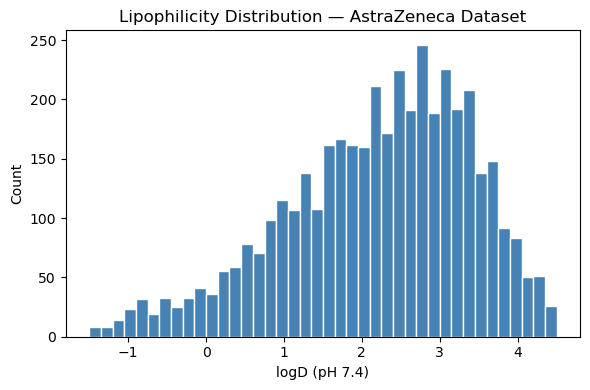

,Drug_ID,Drug,Y
0,CHEMBL596271,Cn1c(CN2CCN(c3ccc(Cl)cc3)CC2)nc2ccccc21,3.54
1,CHEMBL1951080,COc1cc(OC)c(S(=O)(=O)N2c3ccccc3CCC2C)cc1NC(=O)...,-1.18
2,CHEMBL1771,COC(=O)[C@H](c1ccccc1Cl)N1CCc2sccc2C1,3.69
3,CHEMBL317462,OC1(C#Cc2ccc(-c3ccccc3)cc2)CN2CCC1CC2,3.14
4,CHEMBL1940306,CS(=O)(=O)c1ccc(Oc2ccc(C#C[C@]3(O)CN4CCC3CC4)c...,1.51


In [30]:
# ── Load Dataset ──────────────────────────────────────────────────────────────
data = ADME(name='Lipophilicity_AstraZeneca')

# Random split (optimistic baseline)
split_random = data.get_split(method='random')
df_train_r = split_random['train']
df_valid_r = split_random['valid']
df_test_r  = split_random['test']

# Scaffold split (primary evaluation)
split_scaffold = data.get_split(method='scaffold')
df_train_s = split_scaffold['train']
df_valid_s = split_scaffold['valid']
df_test_s  = split_scaffold['test']

# Combined dataframe for cleaning (all unique molecules)
df = pd.concat([df_train_r, df_valid_r, df_test_r], axis=0)
df.reset_index(drop=True, inplace=True)

print(f"Total molecules loaded: {df.shape[0]}")
print(f"Columns: {df.columns.tolist()}")
print(f"\nRandom split  — Train: {len(df_train_r)}, Val: {len(df_valid_r)}, Test: {len(df_test_r)}")
print(f"Scaffold split — Train: {len(df_train_s)}, Val: {len(df_valid_s)}, Test: {len(df_test_s)}")

# Quick look at the target distribution
fig, ax = plt.subplots(figsize=(6, 4))
ax.hist(df['Y'], bins=40, color='steelblue', edgecolor='white')
ax.set_xlabel('logD (pH 7.4)')
ax.set_ylabel('Count')
ax.set_title('Lipophilicity Distribution — AstraZeneca Dataset')
plt.tight_layout()
plt.show()

# Preview dataset
display(df.head())

## Data Cleaning

Rows raw:                  4200
Rows after invalid SMILES: 4200  (removed 0)
Rows after deduplication:  4200  (removed 0)


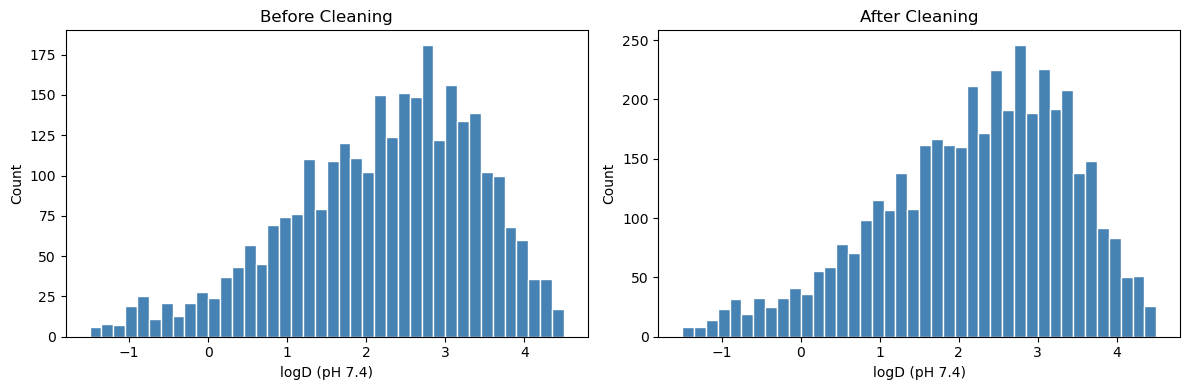

,Drug_ID,Drug,Y,mol,canonical_SMILES
0,CHEMBL596271,Cn1c(CN2CCN(c3ccc(Cl)cc3)CC2)nc2ccccc21,3.54,<rdkit.Chem.rdchem.Mol object at 0x000001987FC...,Cn1c(CN2CCN(c3ccc(Cl)cc3)CC2)nc2ccccc21
1,CHEMBL1951080,COc1cc(OC)c(S(=O)(=O)N2c3ccccc3CCC2C)cc1NC(=O)...,-1.18,<rdkit.Chem.rdchem.Mol object at 0x000001987FC...,COc1cc(OC)c(S(=O)(=O)N2c3ccccc3CCC2C)cc1NC(=O)...
2,CHEMBL1771,COC(=O)[C@H](c1ccccc1Cl)N1CCc2sccc2C1,3.69,<rdkit.Chem.rdchem.Mol object at 0x000001987FC...,COC(=O)[C@H](c1ccccc1Cl)N1CCc2sccc2C1
3,CHEMBL317462,OC1(C#Cc2ccc(-c3ccccc3)cc2)CN2CCC1CC2,3.14,<rdkit.Chem.rdchem.Mol object at 0x000001987FC...,OC1(C#Cc2ccc(-c3ccccc3)cc2)CN2CCC1CC2
4,CHEMBL1940306,CS(=O)(=O)c1ccc(Oc2ccc(C#C[C@]3(O)CN4CCC3CC4)c...,1.51,<rdkit.Chem.rdchem.Mol object at 0x000001987FC...,CS(=O)(=O)c1ccc(Oc2ccc(C#C[C@]3(O)CN4CCC3CC4)c...


In [31]:
# ── Data Cleaning ─────────────────────────────────────────────────────────────
n_rows_raw = df.shape[0]

# Step 1: Convert SMILES to RDKit mol objects, drop invalid SMILES
df['mol'] = df['Drug'].apply(Chem.MolFromSmiles)
df.dropna(subset=['mol'], inplace=True)
n_rows_after_invalid = df.shape[0]

# Step 2: Canonicalize SMILES
df['canonical_SMILES'] = df['mol'].apply(
    lambda x: Chem.MolToSmiles(x, canonical=True)
)

# Step 3: Drop duplicate canonical SMILES
df.drop_duplicates(subset='canonical_SMILES', keep='first', inplace=True)
df.reset_index(drop=True, inplace=True)
n_rows_after_dedup = df.shape[0]

# Report
print(f"Rows raw:                  {n_rows_raw}")
print(f"Rows after invalid SMILES: {n_rows_after_invalid}  "
      f"(removed {n_rows_raw - n_rows_after_invalid})")
print(f"Rows after deduplication:  {n_rows_after_dedup}  "
      f"(removed {n_rows_after_invalid - n_rows_after_dedup})")

# Plot target distribution before vs after cleaning
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(split_random['train']['Y'], bins=40,
             color='steelblue', edgecolor='white')
axes[0].set_title('Before Cleaning')
axes[0].set_xlabel('logD (pH 7.4)')
axes[0].set_ylabel('Count')

axes[1].hist(df['Y'], bins=40,
             color='steelblue', edgecolor='white')
axes[1].set_title('After Cleaning')
axes[1].set_xlabel('logD (pH 7.4)')
axes[1].set_ylabel('Count')

plt.tight_layout()
plt.show()

display(df.head())

## Helper Functions

In [32]:
# ── RDKit ─────────────────────────────────────────────────────────────────────
from rdkit import Chem, RDLogger
from rdkit.Chem import (
    rdMolDescriptors, Descriptors, Crippen,
    MACCSkeys, RDKFingerprint, AllChem,
    Lipinski, GraphDescriptors, Fragments, QED
)
from rdkit.Chem.rdFingerprintGenerator import GetMorganGenerator, AdditionalOutput
from rdkit.Chem.rdMolDescriptors import (
    CalcTPSA, CalcKappa1, CalcKappa2, CalcKappa3,
    CalcChi0v, CalcChi1v, CalcChi2v, CalcChi3v, CalcChi4v,
    CalcChi0n, CalcChi1n, CalcChi2n, CalcChi3n, CalcChi4n,
)

# ── General ───────────────────────────────────────────────────────────────────
import pandas as pd
import numpy as np


def apply_featurizer(df, featurizer, col_name_smiles='SMILES', features_name=None, return_concat=False):
    """
    Apply a featurizer function to a SMILES column in a DataFrame and return the resulting feature matrix.

    Parameters
    ----------
    df : pandas.DataFrame
        Input DataFrame containing a column with SMILES strings.
        
    featurizer : callable
        A function applied to each SMILES string. It must return a fixed-length
        iterable (e.g., list, tuple, numpy array) of numerical features.
        
    col_name_smiles : str, default='SMILES'
        Name of the column in `df` containing SMILES strings.
        
    features_name : str or list of str, optional, default=None
        If a string is provided, feature columns will be named
        `{features_name}_0`, `{features_name}_1`, ..., `{features_name}_n`.
        
        If a list of strings is provided, it must match the number of generated
        features exactly and will be used as column names.
        
        If None, columns will be named `feature_0`, `feature_1`, ..., `feature_n`.
        
    return_concat : bool, default=False
        If True, returns the original DataFrame concatenated with the generated
        feature columns. If False, returns only the feature DataFrame.

    Returns
    -------
    pandas.DataFrame
        A DataFrame containing the generated features, or the concatenation
        of the original DataFrame and the features if `return_concat=True`.

    Raises
    ------
    ValueError
        If `features_name` is a list and its length does not match the number
        of generated features.

    Notes
    -----
    - The `featurizer` must return a fixed-length iterable for every input.
      Inconsistent feature lengths will raise errors when constructing the
      DataFrame.
    - The index of the returned DataFrame matches the index of the input `df`.
    - This function applies the featurizer row-wise using `pandas.Series.apply`,
      which may be slow for very large datasets.
    """

    features_df = pd.DataFrame(df[col_name_smiles].apply(featurizer).tolist(), index=df.index)
    
    if isinstance(features_name, str):
        features_df.columns = [f'{features_name}_{i}' for i in range(features_df.shape[1])]
    elif isinstance(features_name, list):
        if len(features_name) != features_df.shape[1]:
            raise ValueError(f"Length of features_name ({len(features_name)}) does not match number of features ({features_df.shape[1]})")
        features_df.columns = features_name
    else:
        features_df.columns = [f'feature_{i}' for i in range(features_df.shape[1])]
    
    if return_concat:
        return pd.concat([df, features_df], axis=1)
    else:
        return features_df

def smiles2physchem(smiles: str) -> list:
    """
    Compute basic physicochemical features from a molecule's SMILES string.

    Parameters
    ----------
    smiles : str
        A SMILES (Simplified Molecular Input Line Entry System) string representing a chemical molecule.

    Returns
    -------
    list
        A list of 10 physicochemical descriptors in the following order:
        
        1. **logP** (float) – Octanol-water partition coefficient, indicating hydrophobicity. Higher values mean more lipophilic.
        2. **Molecular Weight** (float) – Total molecular mass of the molecule.
        3. **H-Bond Donors** (int) – Number of hydrogen bond donor groups (e.g., –OH, –NH).
        4. **H-Bond Acceptors** (int) – Number of hydrogen bond acceptor atoms (e.g., O, N).
        5. **TPSA** (float) – Topological polar surface area; correlates with drug absorption and permeability.
        6. **Number of Rotatable Bonds** (int) – Flexibility of the molecule; affects conformational freedom.
        7. **Exact Molecular Weight** (float) – Exact mass of the molecule, considering isotopes.
        8. **Number of Aromatic Rings** (int) – Count of aromatic ring structures in the molecule.
        9. **Number of Heteroatoms** (int) – Atoms other than carbon and hydrogen (e.g., N, O, S, P).
        10. **Number of Aliphatic Rings** (int) – Count of non-aromatic ring structures.

    Notes
    -----
    - If the SMILES string cannot be parsed, the function returns a list of 10 `None` values.
    - This function uses RDKit descriptors (`Chem`, `Descriptors`, `Crippen`, `rdMolDescriptors`).
    - Output: ['logp', 'mol_wt', 'hbond_donor', 'hbond_acceptor', 'tpsa', 'num_rotatable_bonds', 'molecular_volume', 'num_aromatic_rings', 'num_heteroatoms', 'num_aliphatic_rings']
    """
    molecule = Chem.MolFromSmiles(smiles)
    if molecule is None:
        return [None] * 10

    logp = Crippen.MolLogP(molecule)
    mol_wt = Descriptors.MolWt(molecule)
    hbond_donor = Descriptors.NumHDonors(molecule)
    hbond_acceptor = Descriptors.NumHAcceptors(molecule)
    tpsa = rdMolDescriptors.CalcTPSA(molecule)
    num_rotatable_bonds = Descriptors.NumRotatableBonds(molecule)
    molecular_volume = Descriptors.ExactMolWt(molecule)
    num_aromatic_rings = Descriptors.NumAromaticRings(molecule)
    num_heteroatoms = Descriptors.NumHeteroatoms(molecule)
    num_aliphatic_rings = Descriptors.NumAliphaticRings(molecule)

    return [logp, mol_wt, hbond_donor, hbond_acceptor, tpsa, num_rotatable_bonds, molecular_volume, num_aromatic_rings, num_heteroatoms, num_aliphatic_rings]

def smiles2morgan(smiles: str, radius: int = 2, fpSize: int = 2048, return_bitInfo: bool = False) -> list:
    """
    Convert a SMILES string into a Morgan fingerprint vector, with optional bit information.

    This function takes a molecular SMILES string, generates the corresponding
    molecule object, and computes its Morgan fingerprint (circular fingerprint)
    as a binary vector of a specified size. Optionally, it can also return the
    mapping of bits to atom environments used to generate the fingerprint.

    Parameters
    ----------
    smiles : str
        A SMILES (Simplified Molecular Input Line Entry System) string
        representing the molecule.
    radius : int, optional, default=2
        The radius of the Morgan fingerprint, defining how many bonds from
        each atom are considered when generating substructures.
    fpSize : int, optional, default=2048
        The size (length) of the output fingerprint vector.
    return_bitInfo : bool, optional, default=False
        If True, also return a dictionary mapping fingerprint bits to the
        atom environments that contributed to them.

    Returns
    -------
    list or tuple
        - If `return_bitInfo` is False, returns a list of integers (0 or 1)
          representing the binary Morgan fingerprint.
        - If `return_bitInfo` is True, returns a tuple `(fingerprint, bitInfoMap)`:
            - `fingerprint`: list of integers (0 or 1) of length `fpSize`
            - `bitInfoMap`: dictionary mapping each bit index to information about
              the atoms/substructures that set that bit.

        If the SMILES string is invalid or cannot be parsed, returns a list
        of `None` values of length `fpSize`.
    """
    molecule = Chem.MolFromSmiles(smiles)
    if molecule is None:
        return [None] * fpSize
    generator = GetMorganGenerator(radius=radius, fpSize=fpSize)

    if return_bitInfo:
        ao = AdditionalOutput()
        ao.AllocateBitInfoMap()
        fp = list(generator.GetFingerprint(molecule, additionalOutput=ao))
        return fp,ao.GetBitInfoMap()
    else:
        fp = list(generator.GetFingerprint(molecule))
        return fp

def smiles2maccs(smiles: str) -> list:
    """
    Generate the MACCS fingerprint for a molecule from its SMILES string.

    Parameters
    ----------
    smiles : str
        A SMILES (Simplified Molecular Input Line Entry System) string representing a chemical molecule.

    Returns
    -------
    list
        A list of 167 bits representing the MACCS structural keys fingerprint of the molecule.
        - Each bit is 0 or 1, indicating the presence or absence of a particular structural feature.
        - The MACCS keys capture common chemical substructures, rings, and functional groups.

    Notes
    -----
    - If the SMILES string cannot be parsed, the function returns a list of 167 `None` values.
    - This function uses RDKit's `MACCSkeys` module to generate the fingerprints.
    - MACCS fingerprints are widely used in cheminformatics for similarity searches and machine learning tasks.

    Examples
    --------
    >>> smiles2maccs('CCO')
    [0, 0, 0, 1, 0, 0, 0, ..., 0]  # 167 bits representing ethanol
    """
    molecule = Chem.MolFromSmiles(smiles)
    if molecule is None:
        return [None] * 167
    return list(MACCSkeys.GenMACCSKeys(molecule))

def smiles2rdkfp(smiles: str, fpSize: int = 2048, maxPath: int = 7, return_bitInfo: bool = False) -> list:
    """
    Convert a SMILES string into an RDKit topological (RDK) fingerprint.

    Parameters
    ----------
    smiles : str
        A SMILES string representing the molecule to be fingerprinted.
    fpSize : int, optional (default=2048)
        The size (number of bits) of the resulting fingerprint.
    maxPath : int, optional (default=7)
        The maximum path length (in bonds) considered when generating the fingerprint.
    return_bitInfo : bool, optional (default=False)
        If True, also return a dictionary mapping fingerprint bits to the atom paths that set them.

    Returns
    -------
    list
        A list of integers (0 or 1) representing the fingerprint bits. If `return_bitInfo=True`, 
        returns a tuple `(fingerprint_list, bitInfo)` where `bitInfo` is a dictionary 
        of the form `{bit_id: [(atom_idx1, atom_idx2, ...), ...]}` mapping bits to the atom paths that contributed to them.

    Notes
    -----
    - If the SMILES string is invalid or cannot be parsed, the function returns a list of `np.nan` 
      values with length equal to `fpSize`.
    - The `bitInfo` dictionary is only populated if `return_bitInfo=True`.
    - This function uses RDKit's `RDKFingerprint` for generating topological fingerprints.

    """
    bitInfo = {}
    try:
        molecule = Chem.MolFromSmiles(smiles)
        if return_bitInfo:
            fp = RDKFingerprint(molecule, fpSize = fpSize, maxPath = maxPath, bitInfo = bitInfo)
        else:
            fp = RDKFingerprint(molecule, fpSize = fpSize, maxPath = maxPath)
        out = list(fp)
    except:
        out = [np.nan]*fpSize
    
    if return_bitInfo:
        return out,bitInfo
    else:
        return out


DESCRIPTOR_NAMES = [
    # --- Lipophilicity (correlated group) ---
    'logp',                       # Wildman-Crippen octanol-water partition coefficient
    'molar_refractivity',         # Crippen molar refractivity
    'logp_rdkit',                 # RDKit built-in logP; slightly different implementation

    # --- Molecular Weight & Size (correlated group) ---
    'mol_wt',                     # Average molecular weight based on atomic masses
    'heavy_atom_mol_wt',          # Molecular weight of heavy (non-H) atoms only
    'heavy_atom_count',           # Number of non-hydrogen atoms
    'num_atoms',                  # Total atom count including explicit hydrogens
    'num_heavy_atoms',            # Heavy atom count via rdMolDescriptors

    # --- Hydrogen Bonding (correlated group) ---
    'hbond_donor',                # Lipinski H-bond donor count (-OH, -NH groups)
    'hbond_acceptor',             # Lipinski H-bond acceptor count (O, N atoms)
    'hbond_donor_rdkit',          # RDKit H-bond donor count; slightly stricter definition
    'hbond_acceptor_rdkit',       # RDKit H-bond acceptor count; slightly stricter definition

    # --- Polarity & Surface Area (correlated group) ---
    'tpsa',                       # Topological polar surface area
    'labute_asa',                 # Labute approximate surface area
    'peoe_vsa1',                  # Surface area contribution from atoms with PEOE partial charge in bin 1
    'peoe_vsa2',                  # Surface area contribution from atoms with PEOE partial charge in bin 2
    'peoe_vsa3',                  # Surface area contribution from atoms with PEOE partial charge in bin 3
    'peoe_vsa4',                  # Surface area contribution from atoms with PEOE partial charge in bin 4
    'peoe_vsa5',                  # Surface area contribution from atoms with PEOE partial charge in bin 5
    'peoe_vsa6',                  # Surface area contribution from atoms with PEOE partial charge in bin 6
    'slogp_vsa1',                 # Surface area contribution from atoms with SlogP contribution in bin 1
    'slogp_vsa2',                 # Surface area contribution from atoms with SlogP contribution in bin 2
    'slogp_vsa3',                 # Surface area contribution from atoms with SlogP contribution in bin 3
    'smr_vsa1',                   # Surface area contribution from atoms with SMR contribution in bin 1
    'smr_vsa2',                   # Surface area contribution from atoms with SMR contribution in bin 2
    'smr_vsa3',                   # Surface area contribution from atoms with SMR contribution in bin 3

    # --- Flexibility & Shape ---
    'num_rotatable_bonds',        # Number of rotatable bonds (Lipinski definition); measure of molecular flexibility
    'num_rotatable_bonds_rdkit',  # Number of rotatable bonds (RDKit definition)
    'kappa1',                     # Hall-Kier kappa index 1; encodes overall molecular shape and size
    'kappa2',                     # Hall-Kier kappa index 2; encodes degree of branching
    'kappa3',                     # Hall-Kier kappa index 3; encodes 3-atom branching patterns

    # --- Connectivity / Topological Indices (highly intercorrelated group) ---
    'chi0v',                      # Valence-weighted zeroth-order chi connectivity index
    'chi1v',                      # Valence-weighted first-order chi connectivity index
    'chi2v',                      # Valence-weighted second-order chi connectivity index
    'chi3v',                      # Valence-weighted third-order chi connectivity index
    'chi4v',                      # Valence-weighted fourth-order chi connectivity index
    'chi0n',                      # Non-H atom zeroth-order chi connectivity index
    'chi1n',                      # Non-H atom first-order chi connectivity index
    'chi2n',                      # Non-H atom second-order chi connectivity index
    'chi3n',                      # Non-H atom third-order chi connectivity index
    'chi4n',                      # Non-H atom fourth-order chi connectivity index
    'ipc',                        # Bonchev-Trinajstic information content index
    'bertz_ct',                   # Bertz complexity index
    'balaban_j',                  # Balaban J topological index; measures molecular branching and cyclicity
    'hallkier_alpha',             # Hall-Kier alpha correction; accounts for atom size deviations from carbon

    # --- Ring Systems (correlated group) ---
    'num_aromatic_rings',         # Number of aromatic rings
    'num_aliphatic_rings',        # Number of aliphatic (non-aromatic) rings
    'num_saturated_rings',        # Number of fully saturated rings; subset of num_aliphatic_rings
    'num_rings',                  # Total ring count (aromatic + aliphatic)
    'num_aromatic_carbocycles',   # Number of aromatic rings containing only carbon; subset of num_aromatic_rings
    'num_aromatic_heterocycles',  # Number of aromatic rings containing heteroatoms
    'num_aliphatic_carbocycles',  # Number of aliphatic carbocyclic rings; subset of num_aliphatic_rings
    'num_aliphatic_heterocycles', # Number of aliphatic rings containing heteroatoms
    'num_saturated_carbocycles',  # Number of saturated carbocyclic rings; subset of num_aliphatic_carbocycles
    'num_saturated_heterocycles', # Number of saturated heterocyclic rings; subset of num_aliphatic_heterocycles
    'ring_count',                 # Total ring count via rdMolDescriptors

    # --- Atom-Type Counts (correlated group) ---
    'num_heteroatoms',            # Total number of non-C, non-H atoms; sum of N, O, S, halogens etc.
    'num_nitrogen',               # Number of nitrogen atoms; subset of num_heteroatoms
    'num_oxygen',                 # Number of oxygen atoms; subset of num_heteroatoms
    'num_sulfur',                 # Number of sulfur atoms; subset of num_heteroatoms
    'num_halogens',               # Total number of halogen atoms (F+Cl+Br+I); subset of num_heteroatoms
    'num_fluorine',               # Number of fluorine atoms; subset of num_halogens
    'num_chlorine',               # Number of chlorine atoms; subset of num_halogens
    'num_bromine',                # Number of bromine atoms; subset of num_halogens
    'fraction_csp3',              # Fraction of sp3 carbons (Fsp3); measure of three-dimensionality

    # --- Charge & Electronic Properties ---
    'max_partial_charge',         # Maximum Gasteiger partial charge over all atoms
    'min_partial_charge',         # Minimum Gasteiger partial charge over all atoms
    'max_abs_partial_charge',     # Maximum absolute Gasteiger partial charge
    'min_abs_partial_charge',     # Minimum absolute Gasteiger partial charge

    # --- Drug-likeness ---
    'qed',                        # Quantitative estimate of drug-likeness (0-1); composite of multiple properties
    'num_lipinskihba',            # Lipinski H-bond acceptor count (explicit RDKit Lipinski definition)
    'num_lipinskihbd',            # Lipinski H-bond donor count (explicit RDKit Lipinski definition)
    'num_stereocenters',          # Number of stereocenters (assigned and unassigned)
    'num_spiro_atoms',            # Number of spiro atoms (atoms shared between two rings via one atom)
    'num_bridgehead_atoms',       # Number of bridgehead atoms (atoms shared between two rings via two+ bonds)

    # --- Fragment / Functional Group Counts (correlated with atom-type counts above) ---
    'fr_NH0',                     # Number of tertiary amines; subset of num_nitrogen
    'fr_NH1',                     # Number of secondary amines; subset of num_nitrogen
    'fr_NH2',                     # Number of primary amines; subset of num_nitrogen
    'fr_Al_OH',                   # Number of aliphatic hydroxyl groups; subset of num_oxygen
    'fr_Al_OH_noTert',            # Number of aliphatic hydroxyl groups excluding tertiary OH
    'fr_Ar_OH',                   # Number of aromatic hydroxyl groups (phenols); subset of num_oxygen
    'fr_ArN',                     # Number of N functional groups attached to aromatics; subset of num_nitrogen
    'fr_Ar_NH',                   # Number of aromatic amine groups
    'fr_C_O',                     # Number of C=O groups (aldehydes, ketones, acids, esters)
    'fr_C_O_noCOO',               # Number of C=O groups excluding carboxylic acids
    'fr_COO',                     # Number of carboxylate groups; subset of fr_C_O
    'fr_COO2',                    # Number of carboxylic acid groups
    'fr_Al_COO',                  # Number of aliphatic carboxylic acids; subset of fr_COO2
    'fr_Ar_COO',                  # Number of aromatic carboxylic acids; subset of fr_COO2
    'fr_halogen',                 # Number of halogen atoms via fragment matching
    'fr_alkyl_halide',            # Number of alkyl halide groups; subset of fr_halogen
    'fr_sulfonamd',               # Number of sulfonamide groups; subset of num_sulfur
    'fr_SH',                      # Number of thiol groups; subset of num_sulfur
    'fr_nitro',                   # Number of nitro groups
    'fr_nitro_arom',              # Number of aromatic nitro groups; subset of fr_nitro
    'fr_nitrile',                 # Number of nitrile groups; subset of num_nitrogen
    'fr_amide',                   # Number of amide groups
    'fr_ester',                   # Number of ester groups
    'fr_ether',                   # Number of ether groups
    'fr_ketone',                  # Number of ketone groups; subset of fr_C_O_noCOO
    'fr_aldehyde',                # Number of aldehyde groups; subset of fr_C_O_noCOO
]


def smiles2physchem_extended(smiles: str) -> list:
    """
    Compute an extended set of physicochemical and topological descriptors from a SMILES string.

    Intentionally includes correlated descriptor groups to serve as a starting point
    for feature selection exercises.

    Parameters
    ----------
    smiles : str
        A SMILES string representing a chemical molecule.

    Returns
    -------
    list
        A list of descriptor values in the order defined by DESCRIPTOR_NAMES.
        Returns a list of None values if the SMILES cannot be parsed.
    """
    molecule = Chem.MolFromSmiles(smiles)
    if molecule is None:
        return [None] * len(DESCRIPTOR_NAMES)

    AllChem.ComputeGasteigerCharges(molecule)

    def count_atoms(symbol):
        return sum(1 for atom in molecule.GetAtoms() if atom.GetSymbol() == symbol)

    return [
        # Lipophilicity
        Crippen.MolLogP(molecule),
        Crippen.MolMR(molecule),
        Descriptors.MolLogP(molecule),
        # Molecular Weight & Size
        Descriptors.MolWt(molecule),
        Descriptors.HeavyAtomMolWt(molecule),
        Descriptors.HeavyAtomCount(molecule),
        molecule.GetNumAtoms(),
        rdMolDescriptors.CalcNumHeavyAtoms(molecule),
        # Hydrogen Bonding
        Descriptors.NumHDonors(molecule),
        Descriptors.NumHAcceptors(molecule),
        rdMolDescriptors.CalcNumHBD(molecule),
        rdMolDescriptors.CalcNumHBA(molecule),
        # Polarity & Surface Area
        CalcTPSA(molecule),
        rdMolDescriptors.CalcLabuteASA(molecule),
        Descriptors.PEOE_VSA1(molecule),
        Descriptors.PEOE_VSA2(molecule),
        Descriptors.PEOE_VSA3(molecule),
        Descriptors.PEOE_VSA4(molecule),
        Descriptors.PEOE_VSA5(molecule),
        Descriptors.PEOE_VSA6(molecule),
        Descriptors.SlogP_VSA1(molecule),
        Descriptors.SlogP_VSA2(molecule),
        Descriptors.SlogP_VSA3(molecule),
        Descriptors.SMR_VSA1(molecule),
        Descriptors.SMR_VSA2(molecule),
        Descriptors.SMR_VSA3(molecule),
        # Flexibility & Shape
        Descriptors.NumRotatableBonds(molecule),
        rdMolDescriptors.CalcNumRotatableBonds(molecule),
        CalcKappa1(molecule),
        CalcKappa2(molecule),
        CalcKappa3(molecule),
        # Connectivity / Topological Indices
        CalcChi0v(molecule),
        CalcChi1v(molecule),
        CalcChi2v(molecule),
        CalcChi3v(molecule),
        CalcChi4v(molecule),
        CalcChi0n(molecule),
        CalcChi1n(molecule),
        CalcChi2n(molecule),
        CalcChi3n(molecule),
        CalcChi4n(molecule),
        GraphDescriptors.Ipc(molecule),
        GraphDescriptors.BertzCT(molecule),
        GraphDescriptors.BalabanJ(molecule),
        rdMolDescriptors.CalcHallKierAlpha(molecule),
        # Ring Systems
        Descriptors.NumAromaticRings(molecule),
        Descriptors.NumAliphaticRings(molecule),
        Descriptors.NumSaturatedRings(molecule),
        rdMolDescriptors.CalcNumAromaticRings(molecule) + rdMolDescriptors.CalcNumAliphaticRings(molecule),
        Descriptors.NumAromaticCarbocycles(molecule),
        Descriptors.NumAromaticHeterocycles(molecule),
        Descriptors.NumAliphaticCarbocycles(molecule),
        Descriptors.NumAliphaticHeterocycles(molecule),
        Descriptors.NumSaturatedCarbocycles(molecule),
        Descriptors.NumSaturatedHeterocycles(molecule),
        rdMolDescriptors.CalcNumRings(molecule),
        # Atom-Type Counts
        Descriptors.NumHeteroatoms(molecule),
        count_atoms('N'),
        count_atoms('O'),
        count_atoms('S'),
        count_atoms('F') + count_atoms('Cl') + count_atoms('Br') + count_atoms('I'),
        count_atoms('F'),
        count_atoms('Cl'),
        count_atoms('Br'),
        rdMolDescriptors.CalcFractionCSP3(molecule),
        # Charge & Electronic
        Descriptors.MaxPartialCharge(molecule),
        Descriptors.MinPartialCharge(molecule),
        Descriptors.MaxAbsPartialCharge(molecule),
        Descriptors.MinAbsPartialCharge(molecule),
        # Drug-likeness
        QED.qed(molecule),
        rdMolDescriptors.CalcNumLipinskiHBA(molecule),
        rdMolDescriptors.CalcNumLipinskiHBD(molecule),
        len(Chem.FindMolChiralCenters(molecule, includeUnassigned=True)),
        rdMolDescriptors.CalcNumSpiroAtoms(molecule),
        rdMolDescriptors.CalcNumBridgeheadAtoms(molecule),
        # Fragments
        Fragments.fr_NH0(molecule),
        Fragments.fr_NH1(molecule),
        Fragments.fr_NH2(molecule),
        Fragments.fr_Al_OH(molecule),
        Fragments.fr_Al_OH_noTert(molecule),
        Fragments.fr_Ar_OH(molecule),
        Fragments.fr_ArN(molecule),
        Fragments.fr_Ar_NH(molecule),
        Fragments.fr_C_O(molecule),
        Fragments.fr_C_O_noCOO(molecule),
        Fragments.fr_COO(molecule),
        Fragments.fr_COO2(molecule),
        Fragments.fr_Al_COO(molecule),
        Fragments.fr_Ar_COO(molecule),
        Fragments.fr_halogen(molecule),
        Fragments.fr_alkyl_halide(molecule),
        Fragments.fr_sulfonamd(molecule),
        Fragments.fr_SH(molecule),
        Fragments.fr_nitro(molecule),
        Fragments.fr_nitro_arom(molecule),
        Fragments.fr_nitrile(molecule),
        Fragments.fr_amide(molecule),
        Fragments.fr_ester(molecule),
        Fragments.fr_ether(molecule),
        Fragments.fr_ketone(molecule),
        Fragments.fr_aldehyde(molecule),
    ]

## Molecular Representations

In [33]:
# ── Molecular Representations ─────────────────────────────────────────────────

# 1. MACCS Keys (166 bits)
df_maccs = apply_featurizer(
    df, featurizer=smiles2maccs,
    col_name_smiles='canonical_SMILES',
    return_concat=False
)
print(f"MACCS keys shape:        {df_maccs.shape}")

# 2. Morgan Fingerprint / ECFP4 (1024 bits, radius=2)
df_morgan = apply_featurizer(
    df, featurizer=lambda s: smiles2morgan(s, radius=2, fpSize=1024),
    col_name_smiles='canonical_SMILES',
    return_concat=False
)
print(f"Morgan FP shape:         {df_morgan.shape}")

# 3. RDKit Fingerprint (2048 bits)
df_rdkfp = apply_featurizer(
    df, featurizer=lambda s: smiles2rdkfp(s, fpSize=2048, maxPath=7),
    col_name_smiles='canonical_SMILES',
    return_concat=False
)
print(f"RDKit FP shape:          {df_rdkfp.shape}")

# 4. Physicochemical Descriptors (10 features)
PHYSCHEM_NAMES = [
    'logp', 'mol_wt', 'hbond_donor', 'hbond_acceptor',
    'tpsa', 'num_rotatable_bonds', 'exact_mol_wt',
    'num_aromatic_rings', 'num_heteroatoms', 'num_aliphatic_rings'
]

df_physchem = apply_featurizer(
    df, featurizer=smiles2physchem,
    col_name_smiles='canonical_SMILES',
    features_name=PHYSCHEM_NAMES,
    return_concat=False
)
print(f"Physicochemical shape:   {df_physchem.shape}")

# 5. Extended Physicochemical Descriptors (for feature selection)
df_physchem_ext = apply_featurizer(
    df, featurizer=smiles2physchem_extended,
    col_name_smiles='canonical_SMILES',
    features_name=DESCRIPTOR_NAMES,
    return_concat=False
)
print(f"Extended physchem shape: {df_physchem_ext.shape}")

MACCS keys shape:        (4200, 167)
Morgan FP shape:         (4200, 1024)
RDKit FP shape:          (4200, 2048)
Physicochemical shape:   (4200, 10)
Extended physchem shape: (4200, 101)


In [34]:
# ── Handle NaNs in extended physicochemical descriptors ──────────────────────
print("NaN counts per feature matrix:")
print(f"  MACCS:        {df_maccs.isna().sum().sum()}")
print(f"  Morgan:       {df_morgan.isna().sum().sum()}")
print(f"  RDKit FP:     {df_rdkfp.isna().sum().sum()}")
print(f"  Physchem ext: {df_physchem_ext.isna().sum().sum()}")

nan_cols = df_physchem_ext.columns[df_physchem_ext.isna().any()].tolist()
print(f"\nFeatures with NaNs: {nan_cols}")

# Fill NaNs with column median across full dataset
df_physchem_ext = df_physchem_ext.fillna(df_physchem_ext.median())

print(f"NaNs after imputation: {df_physchem_ext.isna().sum().sum()}")
print("Ready!")

NaN counts per feature matrix:
  MACCS:        0
  Morgan:       0
  RDKit FP:     0
  Physchem ext: 4

Features with NaNs: ['max_partial_charge', 'min_partial_charge', 'max_abs_partial_charge', 'min_abs_partial_charge']
NaNs after imputation: 0
Ready!


## Splitting Strategies

Random split:
  Train: 2940, Val: 420, Test: 840
  Total: 4200

Scaffold split:
  Train: 2940, Val: 420, Test: 840
  Total: 4200


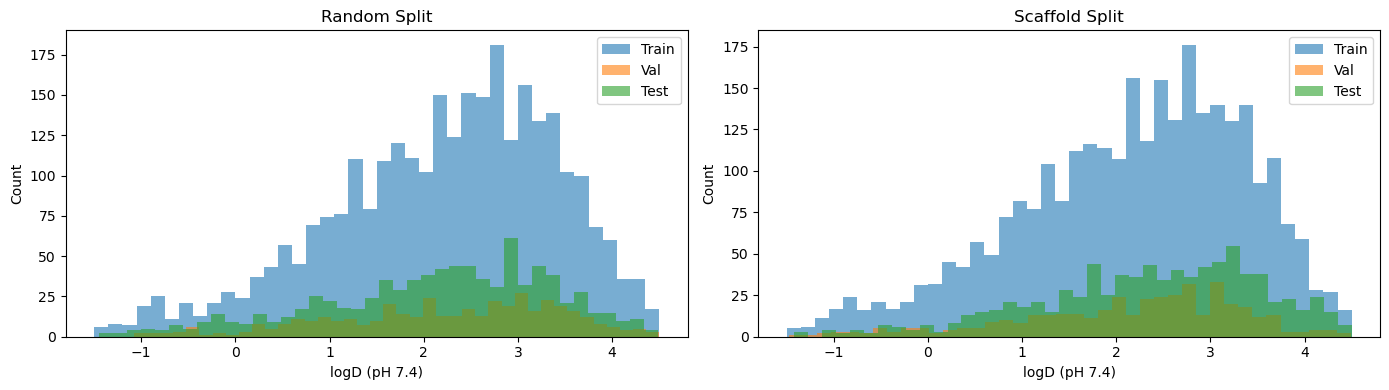

In [35]:
# ── Splitting Strategies ──────────────────────────────────────────────────────
def get_indices(df_full, df_split):
    """
    Given the full cleaned dataframe and a TDC split subset,
    return the indices in df_full that correspond to df_split molecules.
    Matching is done via canonical SMILES.
    """
    split_smiles = set(df_split['Drug'].apply(
        lambda s: Chem.MolToSmiles(Chem.MolFromSmiles(s), canonical=True)
    ))
    return df_full[df_full['canonical_SMILES'].isin(split_smiles)].index.tolist()

# ── Random Split ──────────────────────────────────────────────────────────────
idx_train_r = get_indices(df, df_train_r)
idx_valid_r = get_indices(df, df_valid_r)
idx_test_r  = get_indices(df, df_test_r)

# ── Scaffold Split ────────────────────────────────────────────────────────────
idx_train_s = get_indices(df, df_train_s)
idx_valid_s = get_indices(df, df_valid_s)
idx_test_s  = get_indices(df, df_test_s)

# ── Report ────────────────────────────────────────────────────────────────────
print("Random split:")
print(f"  Train: {len(idx_train_r)}, Val: {len(idx_valid_r)}, Test: {len(idx_test_r)}")
print(f"  Total: {len(idx_train_r) + len(idx_valid_r) + len(idx_test_r)}")

print("\nScaffold split:")
print(f"  Train: {len(idx_train_s)}, Val: {len(idx_valid_s)}, Test: {len(idx_test_s)}")
print(f"  Total: {len(idx_train_s) + len(idx_valid_s) + len(idx_test_s)}")

# ── Visualise target distribution per split ───────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

for ax, (idx_tr, idx_va, idx_te), title in zip(
    axes,
    [(idx_train_r, idx_valid_r, idx_test_r),
     (idx_train_s, idx_valid_s, idx_test_s)],
    ['Random Split', 'Scaffold Split']
):
    ax.hist(df.loc[idx_tr, 'Y'], bins=40, alpha=0.6, label='Train', color='tab:blue')
    ax.hist(df.loc[idx_va, 'Y'], bins=40, alpha=0.6, label='Val',   color='tab:orange')
    ax.hist(df.loc[idx_te, 'Y'], bins=40, alpha=0.6, label='Test',  color='tab:green')
    ax.set_title(title)
    ax.set_xlabel('logD (pH 7.4)')
    ax.set_ylabel('Count')
    ax.legend()

plt.tight_layout()
plt.show()

## Similarity Analysis

Converting fingerprints to RDKit bit vectors...
Computing nearest-neighbour similarities...
Done!


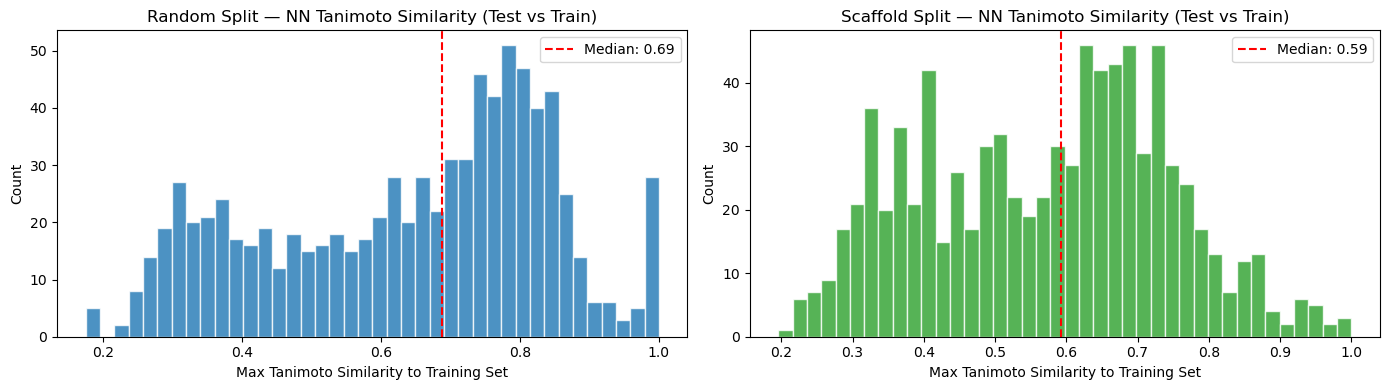

Random   — Mean: 0.639, Median: 0.688, % below 0.4: 18.1%
Scaffold — Mean: 0.571, Median: 0.593, % below 0.4: 20.7%


In [36]:
# ── Train/Test Similarity Analysis ───────────────────────────────────────────
from rdkit.DataStructs import ExplicitBitVect, BulkTanimotoSimilarity

def rows_to_fps(df_features):
    """Convert feature matrix rows to RDKit bit vectors."""
    fps = []
    for _, row in df_features.iterrows():
        fp = ExplicitBitVect(len(row))
        for i, bit in enumerate(row):
            if bit:
                fp.SetBit(i)
        fps.append(fp)
    return fps

def nearest_neighbor_similarity(test_fps, train_fps):
    """For each test fingerprint, return max Tanimoto to any training fingerprint."""
    nn_sims = []
    for fp_test in test_fps:
        sims = BulkTanimotoSimilarity(fp_test, train_fps)
        nn_sims.append(max(sims))
    return np.array(nn_sims)

# Use Morgan fingerprints (same as df_morgan computed earlier)
print("Converting fingerprints to RDKit bit vectors...")
train_fps_r = rows_to_fps(df_morgan.loc[idx_train_r])
test_fps_r  = rows_to_fps(df_morgan.loc[idx_test_r])

train_fps_s = rows_to_fps(df_morgan.loc[idx_train_s])
test_fps_s  = rows_to_fps(df_morgan.loc[idx_test_s])

print("Computing nearest-neighbour similarities...")
nn_sim_random   = nearest_neighbor_similarity(test_fps_r, train_fps_r)
nn_sim_scaffold = nearest_neighbor_similarity(test_fps_s, train_fps_s)
print("Done!")

# Store for later use in applicability domain
df.loc[idx_test_r, 'nn_sim_random']   = nn_sim_random
df.loc[idx_test_s, 'nn_sim_scaffold'] = nn_sim_scaffold

# ── Plot ──────────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

for ax, nn_sim, title, color in zip(
    axes,
    [nn_sim_random, nn_sim_scaffold],
    ['Random Split', 'Scaffold Split'],
    ['tab:blue', 'tab:green']
):
    ax.hist(nn_sim, bins=40, color=color, edgecolor='white', alpha=0.8)
    ax.axvline(np.median(nn_sim), color='red', linestyle='--',
               label=f'Median: {np.median(nn_sim):.2f}')
    ax.set_title(f'{title} — NN Tanimoto Similarity (Test vs Train)')
    ax.set_xlabel('Max Tanimoto Similarity to Training Set')
    ax.set_ylabel('Count')
    ax.legend()

plt.tight_layout()
plt.show()

# ── Summary ───────────────────────────────────────────────────────────────────
for name, nn_sim in [('Random  ', nn_sim_random), ('Scaffold', nn_sim_scaffold)]:
    print(f"{name} — Mean: {nn_sim.mean():.3f}, "
          f"Median: {np.median(nn_sim):.3f}, "
          f"% below 0.4: {(nn_sim < 0.4).mean()*100:.1f}%")

## Model Baseline

In [37]:
# ── Baseline Model — Linear Regression on All Features ───────────────────────
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, r2_score
from copy import deepcopy

# ── Parameters ────────────────────────────────────────────────────────────────
random_state = 42
TARGET_COL   = 'Y'

# ── Random split baseline ─────────────────────────────────────────────────────
results_baseline = {}

for enc_name, df_enc in [('MACCS',        df_maccs),
                          ('Morgan',       df_morgan),
                          ('RDKit_FP',     df_rdkfp),
                          ('Physchem_all', df_physchem_ext)]:

    # Get train/test sets
    X_train = df_enc.loc[idx_train_r].values
    y_train = df.loc[idx_train_r, TARGET_COL].values
    X_test  = df_enc.loc[idx_test_r].values
    y_test  = df.loc[idx_test_r,  TARGET_COL].values

    # Apply scaling for physicochemical descriptors only
    if enc_name == 'Physchem_all':
        scaler  = StandardScaler()
        X_train = scaler.fit_transform(X_train)
        X_test  = scaler.transform(X_test)

    # Train
    model = LinearRegression()
    model.fit(X_train, y_train)

    # Evaluate
    y_pred  = model.predict(X_test)
    mae     = mean_absolute_error(y_test, y_pred)
    r2      = r2_score(y_test, y_pred)

    results_baseline[enc_name] = {
        'MAE':   mae,
        'R2':    r2,
        'model': model,
    }

    print(f"{enc_name:<15} MAE: {mae:.3f}   R²: {r2:.3f}")

# ── Summary table ─────────────────────────────────────────────────────────────
print("\nBaseline Summary (Linear Regression, Random Split, All Features):")
print(f"{'Encoding':<15} {'MAE':>8} {'R²':>8}")
print("-" * 35)
for enc_name, res in results_baseline.items():
    print(f"{enc_name:<15} {res['MAE']:>8.3f} {res['R2']:>8.3f}")

MACCS           MAE: 0.772   R²: 0.380
Morgan          MAE: 0.764   R²: 0.303
RDKit_FP        MAE: 1.232   R²: -0.860
Physchem_all    MAE: 0.691   R²: 0.470

Baseline Summary (Linear Regression, Random Split, All Features):
Encoding             MAE       R²
-----------------------------------
MACCS              0.772    0.380
Morgan             0.764    0.303
RDKit_FP           1.232   -0.860
Physchem_all       0.691    0.470


check the rdkit negative value, use val set to stop the 

## Feature Selection

In [45]:
# ── Parameters ────────────────────────────────────────────────────────────────
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_val_score
from sklearn.inspection import permutation_importance
from scipy.stats import spearmanr
import warnings
warnings.filterwarnings('ignore')

random_state = 42
TARGET_COL   = 'Y'

# Model used for feature selection — Linear Regression (baseline model)
MODEL = LinearRegression()

# Feature selection parameters
CV_FOLDS                = 5
MAX_FEATURES            = 60  # first tried with 40 but the curve didn't plateau, so increased to 60 to see if it plateaus by then
THRESHOLD_CORR_FEATURES = 0.7

# Physicochemical descriptor names (basic 10 features)
PHYSCHEM_NAMES = [
    'logp', 'mol_wt', 'hbond_donor', 'hbond_acceptor',
    'tpsa', 'num_rotatable_bonds', 'exact_mol_wt',
    'num_aromatic_rings', 'num_heteroatoms', 'num_aliphatic_rings'
]

### Helper Funcitons

In [41]:
def spearman_corr_matrix(X: pd.DataFrame) -> pd.DataFrame:
    """
    Compute the pairwise Spearman correlation matrix for all columns of X.

    Parameters
    ----------
    X : pd.DataFrame of shape (n_samples, n_features)
        Feature matrix. All columns must be numeric.

    Returns
    -------
    corr : pd.DataFrame of shape (n_features, n_features)
        Symmetric matrix of Spearman correlation coefficients in [-1, 1].
    """
    corr, _ = spearmanr(X)
    return pd.DataFrame(corr, index=X.columns, columns=X.columns)


def permutation_importance_df(
    model,
    X: pd.DataFrame,
    y: pd.Series,
    n_repeats: int = 10,
    random_state: int = 42,
) -> pd.DataFrame:
    """
    Compute permutation feature importance and return a tidy DataFrame.

    Parameters
    ----------
    model : fitted sklearn estimator
    X : pd.DataFrame of shape (n_samples, n_features)
    y : pd.Series of shape (n_samples,)
    n_repeats : int
        Number of times each feature is permuted.
    random_state : int

    Returns
    -------
    df_imp : pd.DataFrame
        Columns: 'feature', 'importance_mean', 'importance_std'.
        Sorted by importance_mean descending.
    """
    result = permutation_importance(
        model, X, y,
        n_repeats=n_repeats,
        random_state=random_state,
        scoring='r2',
    )
    df_imp = pd.DataFrame({
        'feature':          X.columns,
        'importance_mean':  result.importances_mean,
        'importance_std':   result.importances_std,
    }).sort_values('importance_mean', ascending=False).reset_index(drop=True)
    return df_imp


def forward_selection(
    X_train: pd.DataFrame,
    y_train: pd.Series,
    max_features: int = 10,
    cv: int = 5,
    random_state: int = 42,
    model = MODEL
) -> list:
    """
    Greedy forward feature selection using cross-validated R² as criterion.

    At each round the feature that maximises CV R² when added to the
    current selected set is chosen. Selection stops when max_features
    is reached.

    Parameters
    ----------
    X_train : pd.DataFrame of shape (n_samples, n_features)
    y_train : pd.Series of shape (n_samples,)
    max_features : int
        Maximum number of features to select.
    cv : int
        Number of cross-validation folds.
    random_state : int

    Returns
    -------
    selected : list of str
        Ordered list of selected feature names.
    scores : list of float
        CV R² score after adding each selected feature.
    """
    remaining = list(X_train.columns)
    selected  = []
    scores    = []

    while len(selected) < max_features and remaining:
        best_score   = -np.inf
        best_feature = None

        for feature in remaining:
            candidate = selected + [feature]
            cv_scores = cross_val_score(
                model, X_train[candidate], y_train,
                cv=cv, scoring='r2',
            )
            score = cv_scores.mean()
            if score > best_score:
                best_score   = score
                best_feature = feature

        selected.append(best_feature)
        remaining.remove(best_feature)
        scores.append(best_score)

    return selected, scores


def clustered_forward_selection(
    X_train: pd.DataFrame,
    y_train: pd.Series,
    corr_matrix: pd.DataFrame,
    corr_threshold: float = THRESHOLD_CORR_FEATURES,
    max_features: int = 10,
    cv: int = 5,
    random_state: int = 42,
    model = MODEL,
) -> list:
    """
    Clustered forward feature selection.

    Features are first grouped by correlation using a threshold on the
    absolute Spearman correlation matrix. At each round only one candidate
    per cluster is considered (the one not yet selected from that cluster).
    The candidate that maximises CV R² is added to the selected set and its
    cluster is locked — no further candidates are drawn from it until all
    other clusters have contributed a feature.

    Parameters
    ----------
    X_train : pd.DataFrame of shape (n_samples, n_features)
    y_train : pd.Series of shape (n_samples,)
    corr_matrix : pd.DataFrame
        Precomputed Spearman correlation matrix (from spearman_corr_matrix).
    corr_threshold : float
        Features with |correlation| >= corr_threshold are placed in the
        same cluster.
    max_features : int
        Maximum number of features to select.
    cv : int
        Number of cross-validation folds.
    random_state : int

    Returns
    -------
    selected : list of str
        Ordered list of selected feature names.
    scores : list of float
        CV R² score after adding each selected feature.
    cluster_labels : dict
        Mapping from feature name to cluster id.
    """
    features = list(X_train.columns)
    abs_corr = corr_matrix.abs()

    # Step 1: assign each feature to a cluster
    cluster_labels = {}
    cluster_id     = 0
    unassigned     = set(features)

    for feat in features:
        if feat not in unassigned:
            continue
        correlated = set(
            abs_corr.index[abs_corr[feat] >= corr_threshold].tolist()
        ) & unassigned
        for f in correlated:
            cluster_labels[f] = cluster_id
        unassigned -= correlated
        cluster_id += 1

    # Step 2: greedy forward selection with one candidate per cluster
    selected         = []
    scores           = []
    locked_clusters  = set()

    while len(selected) < max_features:
        available_clusters = [
            cid for cid in set(cluster_labels.values())
            if cid not in locked_clusters
        ]
        if not available_clusters:
            break

        # one candidate per available cluster
        candidates = []
        for cid in available_clusters:
            cluster_features = [
                f for f, c in cluster_labels.items()
                if c == cid and f not in selected
            ]
            if not cluster_features:
                continue

            best_cluster_score   = -np.inf
            best_cluster_feature = None
            for f in cluster_features:
                score    = cross_val_score(
                    model, X_train[[f]], y_train,
                    cv=cv, scoring='r2',
                ).mean()
                if score > best_cluster_score:
                    best_cluster_score   = score
                    best_cluster_feature = f
            if best_cluster_feature is not None:
                candidates.append(best_cluster_feature)

        if not candidates:
            break

        # evaluate each candidate in context and pick the best one
        best_score   = -np.inf
        best_feature = None

        for feature in candidates:
            candidate_set = selected + [feature]
            cv_score      = cross_val_score(
                model, X_train[candidate_set], y_train,
                cv=cv, scoring='r2',
            ).mean()
            if cv_score > best_score:
                best_score   = cv_score
                best_feature = feature

        if best_feature is None:
            break

        selected.append(best_feature)
        scores.append(best_score)
        locked_clusters.add(cluster_labels[best_feature])

    return selected, scores, cluster_labels


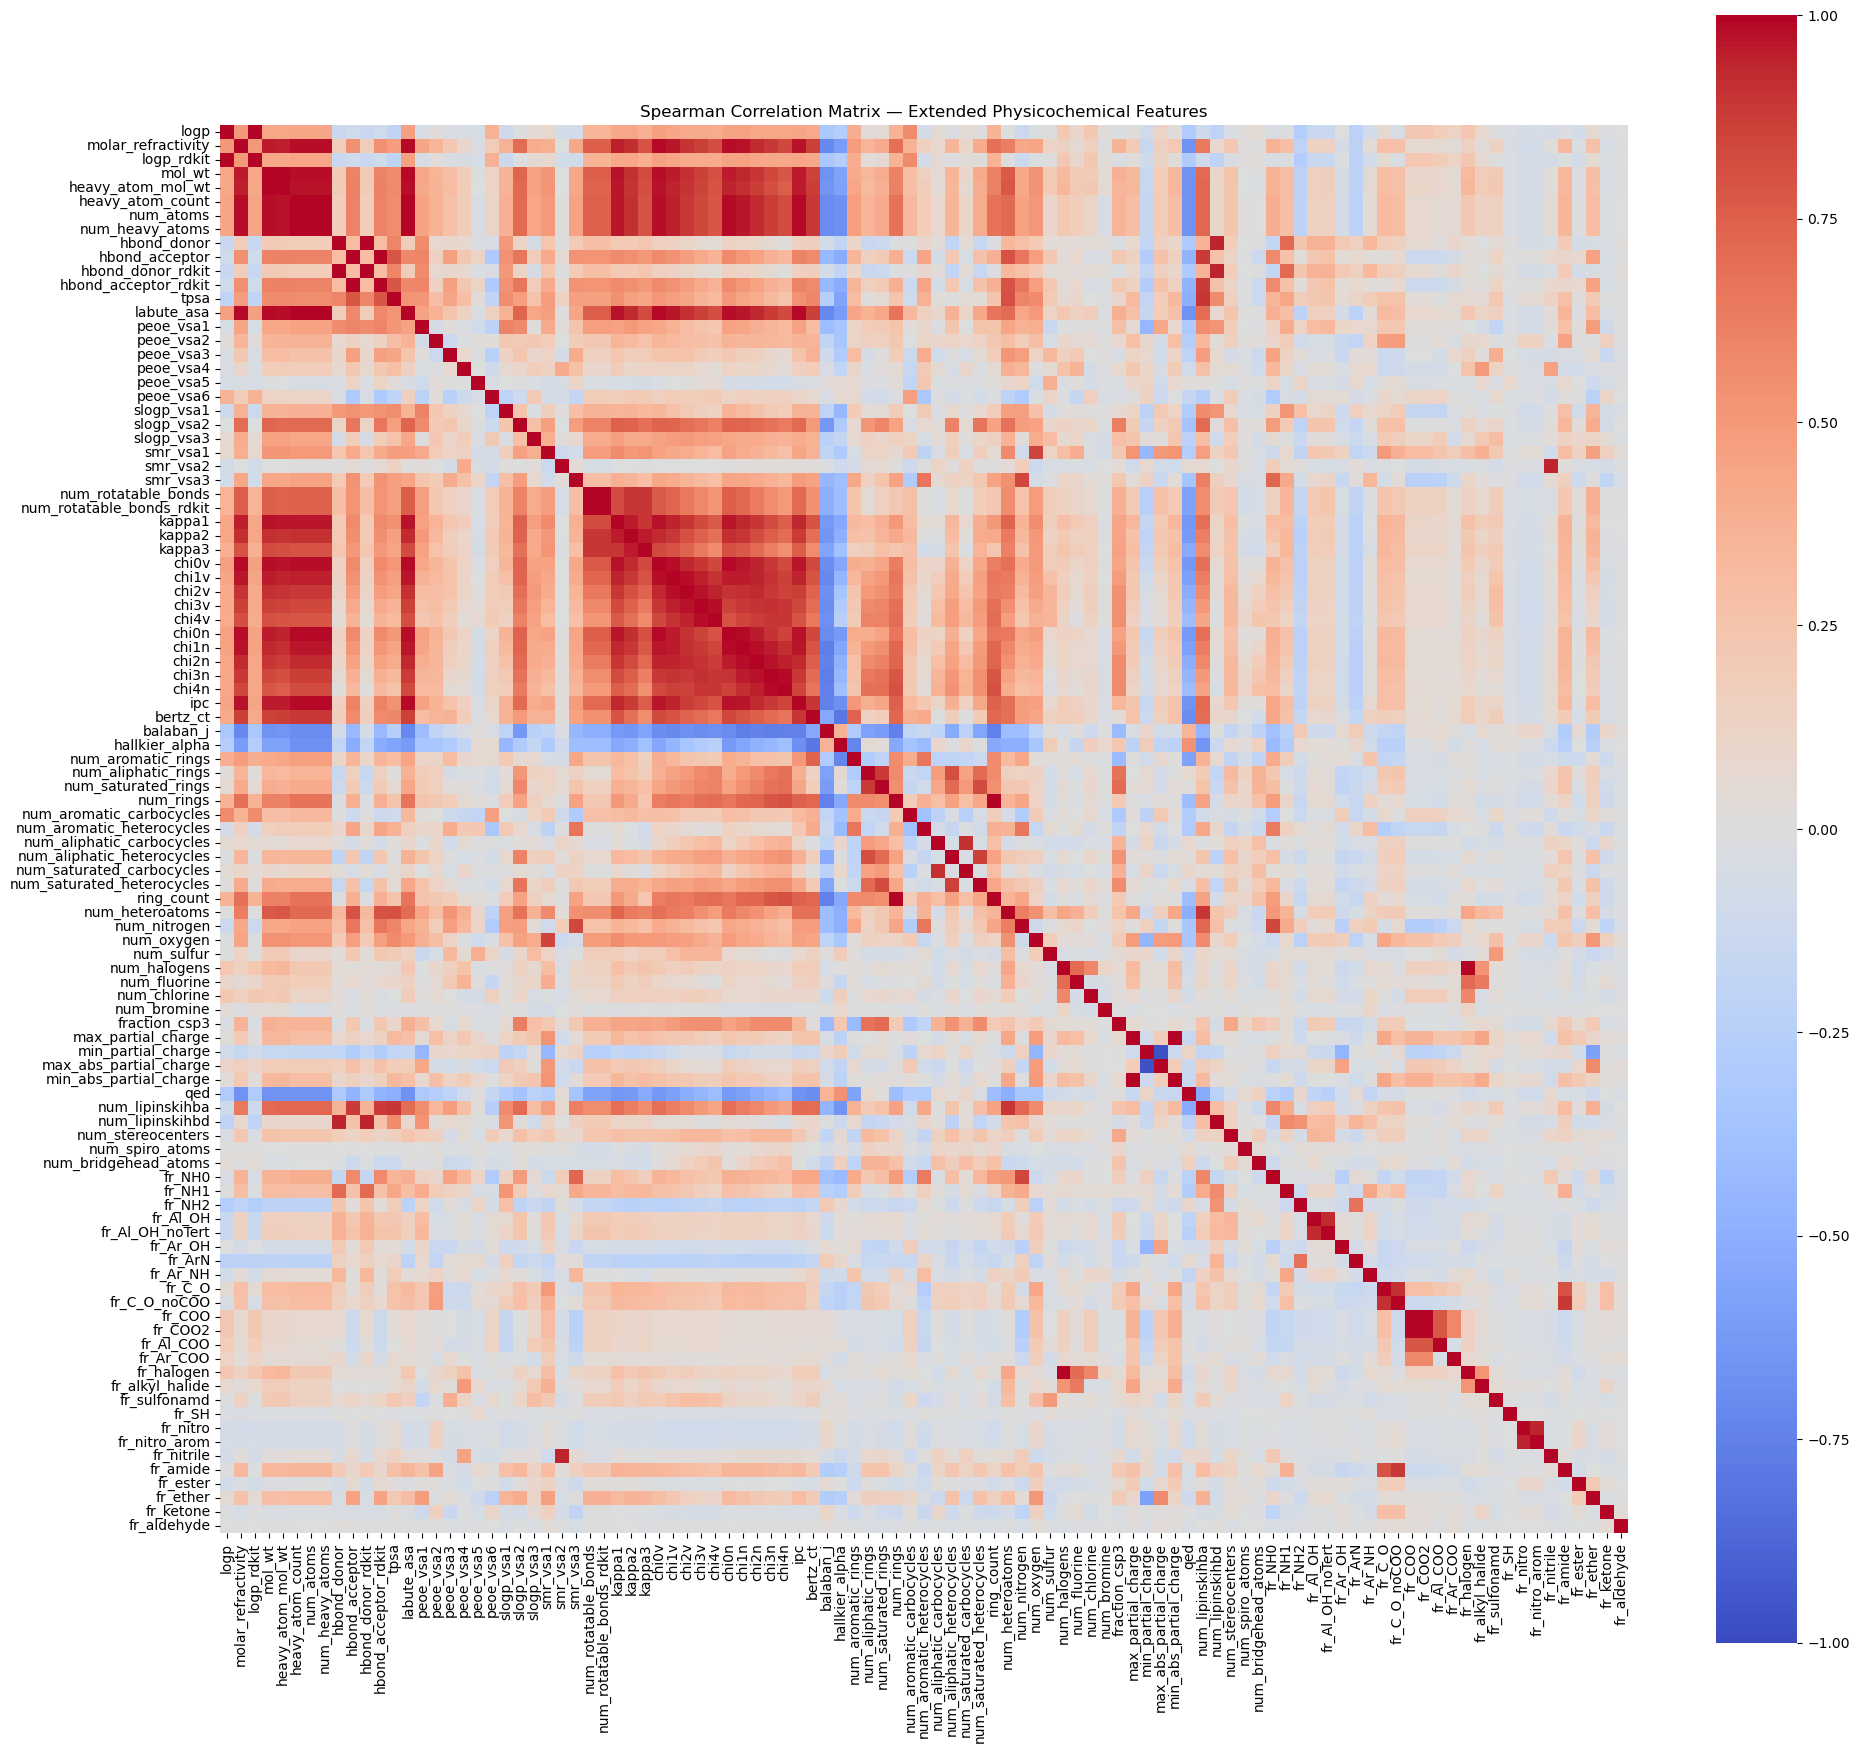

Training set shape: (2940, 101)
Number of features: 101


In [42]:
# ── Feature Selection — Step 1: Correlation Matrix ───────────────────────────

# Use random training split only — never touch test set!
X_fs = df_physchem_ext.loc[idx_train_r]
y_fs = df.loc[idx_train_r, TARGET_COL]

# Compute Spearman correlation matrix
corr = spearman_corr_matrix(X_fs)

# Plot heatmap
fig, ax = plt.subplots(figsize=(20, 18))
sns.heatmap(
    corr,
    annot=False,
    cmap='coolwarm', center=0, vmin=-1, vmax=1,
    square=True, ax=ax,
    xticklabels=DESCRIPTOR_NAMES,
    yticklabels=DESCRIPTOR_NAMES,
)
ax.set_title('Spearman Correlation Matrix — Extended Physicochemical Features')
plt.tight_layout()
plt.show()

print(f"Training set shape: {X_fs.shape}")
print(f"Number of features: {len(DESCRIPTOR_NAMES)}")

In [46]:
# ── Feature Selection — Step 2: Three Methods ────────────────────────────────

# Method 1: Filter
corr_with_target = spearmanr(X_fs, y_fs)[0][:-1, -1]
filter_ranking = pd.Series(
    np.abs(corr_with_target),
    index=DESCRIPTOR_NAMES,
).sort_values(ascending=False)

selected_filter = filter_ranking.index.tolist()
print("Filter — top 20 features by correlation with logD:")
print(filter_ranking.head(20))

# Method 2: Forward Selection
print("\nRunning Forward Selection...")
selected_fs, scores_fs = forward_selection(
    X_fs, y_fs,
    max_features=MAX_FEATURES,
    cv=CV_FOLDS,
    random_state=random_state,
)
opt_nr_var_fs    = np.argmax(scores_fs) + 1
best_selected_fs = selected_fs[:opt_nr_var_fs]
print(f"\nFS optimal: {opt_nr_var_fs} features (CV R²={scores_fs[opt_nr_var_fs-1]:.3f})")

# Method 3: Clustered Forward Selection
print("\nRunning Clustered Forward Selection...")
selected_cfs, scores_cfs, cluster_labels = clustered_forward_selection(
    X_fs, y_fs,
    corr_matrix=corr,
    corr_threshold=THRESHOLD_CORR_FEATURES,
    max_features=MAX_FEATURES,
    cv=CV_FOLDS,
    random_state=random_state,
)
opt_nr_var_cfs    = np.argmax(scores_cfs) + 1
best_selected_cfs = selected_cfs[:opt_nr_var_cfs]
print(f"\nCFS optimal: {opt_nr_var_cfs} features (CV R²={scores_cfs[opt_nr_var_cfs-1]:.3f})")
print(f"Number of clusters found: {len(set(cluster_labels.values()))}")

Filter — top 20 features by correlation with logD:
logp                        0.403145
logp_rdkit                  0.403145
fr_COO                      0.307308
fr_COO2                     0.307308
num_aromatic_rings          0.298055
num_rings                   0.260134
ring_count                  0.260134
fr_Al_COO                   0.243460
balaban_j                   0.227378
num_lipinskihbd             0.216977
hbond_donor                 0.197446
hbond_donor_rdkit           0.197446
ipc                         0.196342
hallkier_alpha              0.195184
bertz_ct                    0.192342
molar_refractivity          0.191802
num_aromatic_carbocycles    0.184926
labute_asa                  0.175777
chi1n                       0.175066
fr_Ar_COO                   0.174528
dtype: float64

Running Forward Selection...

FS optimal: 50 features (CV R²=0.471)

Running Clustered Forward Selection...

CFS optimal: 33 features (CV R²=0.440)
Number of clusters found: 49


graph to see how the number of descriptor affects the perormance